# AIDA 1141 Project Exercise 09 – Review Queue and Threshold

**Question:** Which flagging thresholds and review rules should decide which onboarding assessments are suggested for follow-up, which receive a second look, and which are left for normal monitoring?

This notebook compares thresholds for the Exercise 06 model and the Exercise 05 days rule on validation data, chooses both thresholds with the same rule, defines a three-tier review policy, and freezes every setting before test data is used. The frozen model, thresholds, and policy are then evaluated once on the test set.

Follow-up suggestions are generated automatically, but no follow-up is automatic: a person confirms every follow-up. The tiers decide how prominently each assessment is shown for review. All results describe methods applied to simulated outcomes, not real employees or HR performance.

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from IPython.display import display

EX02 = Path("../02-synthetic-request-records")
EX05 = Path("../05-simple-routing-baseline")
EX06 = Path("../06-model-training-and-split")
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

read = lambda name: pd.read_csv(EX02 / "data" / name, keep_default_na=False, na_values=[""])
requests = read("requests.csv")
assessments = read("assessments.csv")
employee_split = pd.read_csv(EX05 / "outputs" / "employee_split.csv")
rule_thresholds = pd.read_csv(EX05 / "outputs" / "rule_thresholds.csv")
feature_list = pd.read_csv(EX06 / "outputs" / "feature_list.csv")
settings = pd.read_csv(EX06 / "outputs" / "model_settings.csv", index_col=0)["value"]
ex06_validation = pd.read_csv(EX06 / "outputs" / "validation_predictions.csv")
model = joblib.load(EX06 / "outputs" / "model.joblib")   # saved by this project in Exercise 06

FEATURES = feature_list["feature"].tolist()
CATEGORICAL = feature_list.loc[feature_list["type"] == "categorical", "feature"].tolist()
REQUEST_COLUMNS = list(dict.fromkeys([f for f in FEATURES if f in requests.columns] + ["task_type"]))
data = (assessments
        .merge(requests[["request_id", "employee_id"] + REQUEST_COLUMNS]
               .rename(columns={"employee_id": "request_employee_id"}),
               on="request_id", how="left", validate="many_to_one")
        .merge(employee_split, on="employee_id", how="left", validate="many_to_one"))
data["early_warning"] = ~data["past_deadline_at_assessment"]
print(f"Loaded {len(data):,} assessments")

Loaded 2,579 assessments


## A. Input checks and model reload

Before any scoring, the inputs are checked: each package version recorded with the Exercise 06 model matches the installed version, assessment IDs are unique, assessment and request employee IDs agree, every assessment has a split, features are complete, labels are True/False, and each task has one label.

The saved Exercise 06 model is then used to rescore the validation assessments. The rescored probabilities must match the ones saved in Exercise 06 within a tolerance of 1e-12, confirming that the same model is being used. Test assessments are not scored until the policy is frozen in Part C.

In [2]:
saved_versions = dict(item.strip().rsplit(" ", 1) for item in settings["package_versions"].split(";"))
installed_versions = {"scikit-learn": sklearn.__version__, "pandas": pd.__version__, "NumPy": np.__version__,
                      "joblib": joblib.__version__, "SciPy": scipy.__version__}
input_checks = pd.Series({
    **{f"{package} version matches the saved model ({version})": installed_versions[package] == version
       for package, version in saved_versions.items()},
    "One row per assessment": data["assessment_id"].is_unique,
    "Assessment and request employee IDs agree": (data["employee_id"] == data["request_employee_id"]).all(),
    "Every assessment has a split": data["split"].notna().all(),
    "No missing feature values": data[FEATURES].notna().all().all(),
    "Label and early-warning columns are True/False only":
        all(data[c].dtype == bool for c in ["at_risk", "past_deadline_at_assessment"]),
    "Each task has one label": data.groupby("request_id")["at_risk"].nunique().eq(1).all(),
}, name="passed")
assert input_checks.all(), "An input check failed."

def model_frame(rows):
    """Feature columns, with categories (including True/False) treated as text labels, as in Exercise 06."""
    return rows[FEATURES].astype({c: str for c in CATEGORICAL})

validation = data[data["split"] == "validation"].copy()
validation["risk_probability"] = model.predict_proba(model_frame(validation))[:, 1]
matched = validation.merge(ex06_validation[["assessment_id", "risk_probability"]], on="assessment_id",
                           suffixes=("", "_ex06"), validate="one_to_one")
reload_checks = pd.Series({
    "526 validation assessments, all matched to Exercise 06": len(validation) == 526 and len(matched) == 526,
    "Rescored probabilities match Exercise 06 within 1e-12":
        np.allclose(matched["risk_probability"], matched["risk_probability_ex06"], atol=1e-12, rtol=0),
}, name="passed")
assert reload_checks.all(), "The reloaded model does not reproduce Exercise 06."
pd.concat([input_checks, reload_checks]).to_frame()

,passed
scikit-learn version matches the saved model (1.9.1),True
pandas version matches the saved model (3.0.6),True
NumPy version matches the saved model (2.5.3),True
joblib version matches the saved model (1.6.0),True
SciPy version matches the saved model (1.18.1),True
One row per assessment,True
Assessment and request employee IDs agree,True
Every assessment has a split,True
No missing feature values,True
Label and early-warning columns are True/False only,True


## B. Threshold comparison on validation

Both methods are compared across a range of thresholds on the 505 validation early-warning assessments: the model flags an assessment when its estimated risk probability is at or above the threshold, and the days rule flags it when the weekday count until start is at or below the threshold. For each threshold, the table shows flagged assessments, unique tasks flagged, all four confusion counts, recall, precision, and the number of at-risk tasks never flagged. The original thresholds from Exercises 05 and 06 are labelled.

This grid illustrates the trade-off; it is too coarse to identify the fewest flags that meet 90% recall. Part C selects the final thresholds from every distinct validation score (with tied scores kept together) and every available weekday count. Raising the model's threshold, or lowering the rule's, reduces flags but can miss more at-risk cases; the chart shows that trade-off for both methods on this validation set.

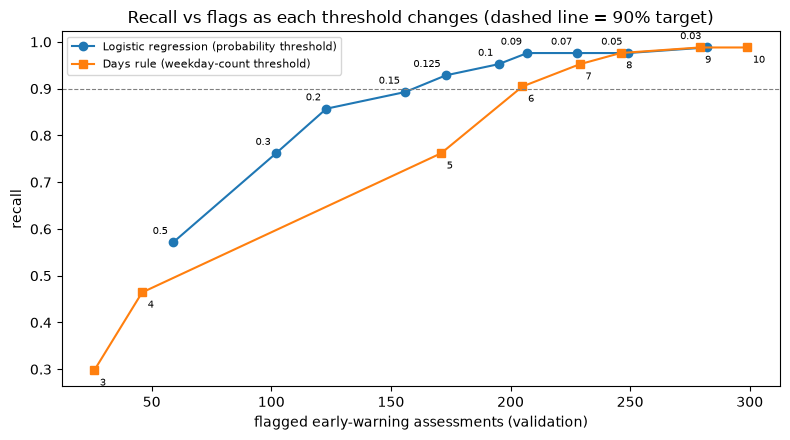

,method,threshold,note,flagged_assessments,flagged_%,unique_tasks_flagged,TP,FP,FN,TN,recall,precision,at_risk_tasks_missed
0,logistic_regression,0.030,,282,55.842,185,83,199,1,222,0.988,0.294,0
1,logistic_regression,0.050,,249,49.307,167,82,167,2,254,0.976,0.329,1
2,logistic_regression,0.070,,228,45.149,157,82,146,2,275,0.976,0.360,1
3,logistic_regression,0.090,,207,40.990,146,82,125,2,296,0.976,0.396,1
4,logistic_regression,0.100,,195,38.614,141,80,115,4,306,0.952,0.410,2
5,logistic_regression,0.125,original Exercise 06 threshold,173,34.257,129,78,95,6,326,0.929,0.451,2
6,logistic_regression,0.150,,156,30.891,121,75,81,9,340,0.893,0.481,3
7,logistic_regression,0.200,,123,24.356,97,72,51,12,370,0.857,0.585,5
8,logistic_regression,0.300,,102,20.198,85,64,38,20,383,0.762,0.627,8
9,logistic_regression,0.500,,59,11.683,56,48,11,36,410,0.571,0.814,18


In [3]:
early = validation[validation["early_warning"]]
ORIGINAL_MODEL_THRESHOLD = float(settings["threshold"])
ORIGINAL_DAYS_THRESHOLD = int(rule_thresholds.query("employee_type == 'all'")["threshold"].item())

def policy_counts(flagged, rows):
    """Review volume and outcomes when the given assessments are flagged."""
    y = rows["at_risk"]
    tp, fp = int((flagged & y).sum()), int((flagged & ~y).sum())
    fn, tn = int((~flagged & y).sum()), int((~flagged & ~y).sum())
    tasks = rows.assign(flag=flagged).groupby("request_id").agg(at_risk=("at_risk", "first"), flag=("flag", "any"))
    return {"flagged_assessments": int(flagged.sum()), "flagged_%": flagged.mean() * 100,
            "unique_tasks_flagged": int(tasks["flag"].sum()), "TP": tp, "FP": fp, "FN": fn, "TN": tn,
            "recall": tp / (tp + fn) if tp + fn else np.nan, "precision": tp / (tp + fp) if tp + fp else np.nan,
            "at_risk_tasks_missed": int((tasks["at_risk"] & ~tasks["flag"]).sum())}

MODEL_GRID = sorted({0.03, 0.05, 0.07, 0.09, 0.10, 0.15, 0.20, 0.30, 0.50, ORIGINAL_MODEL_THRESHOLD})
DAYS_GRID = sorted(set(range(3, 11)) | {ORIGINAL_DAYS_THRESHOLD})
threshold_comparison = pd.DataFrame(
    [{"method": "logistic_regression", "threshold": t,
      "note": "original Exercise 06 threshold" if t == ORIGINAL_MODEL_THRESHOLD else "",
      **policy_counts(early["risk_probability"] >= t, early)} for t in MODEL_GRID]
    + [{"method": "days_until_start_rule", "threshold": k,
        "note": "original Exercise 05 threshold" if k == ORIGINAL_DAYS_THRESHOLD else "",
        **policy_counts(early["business_days_until_start"] <= k, early)} for k in DAYS_GRID])
threshold_comparison.round(4).to_csv(OUTPUT_DIR / "threshold_comparison_validation.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4.5))
for method, label, marker, offset in [("logistic_regression", "Logistic regression (probability threshold)", "o", (-4, 6)),
                                       ("days_until_start_rule", "Days rule (weekday-count threshold)", "s", (4, -11))]:
    sub = threshold_comparison[threshold_comparison["method"] == method]
    ax.plot(sub["flagged_assessments"], sub["recall"], marker=marker, label=label)
    for _, r in sub.iterrows():
        ax.annotate(f"{r['threshold']:.3g}", (r["flagged_assessments"], r["recall"]), textcoords="offset points",
                    xytext=offset, fontsize=7, ha="left" if offset[0] > 0 else "right")
ax.axhline(0.90, color="grey", ls="--", lw=0.8)
ax.set_xlabel("flagged early-warning assessments (validation)")
ax.set_ylabel("recall")
ax.set_title("Recall vs flags as each threshold changes (dashed line = 90% target)")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "threshold_tradeoff.png", dpi=120)
plt.show()

threshold_comparison.round(3)

## C. Choose thresholds and define the candidate policy

Both methods get the same tuning rule on validation: the threshold that reaches at least 90% recall with the fewest flags. Because the methods flag in opposite directions, that means the **highest** probability threshold for the model (chosen from every distinct validation score, with tied scores flagged together) and the **smallest** weekday count for the days rule (chosen from every available count).

The three-tier review policy is a fictional prioritization assumption. No tier is automatic; a person confirms every follow-up.

- **Tier 1 – Follow-up suggested:** the model's estimated risk is at or above its threshold.
- **Tier 2 – Second look:** not tier 1, and at least one review reason applies. **Near threshold:** the estimated risk is at least half the threshold. This band is exploratory and is not a confidence interval. **Methods disagree:** the days rule flags the assessment. **High impact:** 2 or fewer weekday counts until start for any task, or 5 or fewer for payroll, system access, or workplace access tasks. This high-impact rule is an invented prioritization: time-critical cases, and tasks that affect whether a new employee can be paid or start work. It does not imply that other tasks, such as equipment, are unimportant.
- **Tier 3 – No flag:** all other early-warning assessments, which remain visible for normal monitoring.

Tier 1 takes precedence over tier 2, and tier 2 over tier 3, so each early-warning assessment receives one tier. A task takes the highest tier of any of its early-warning assessments. Overdue assessments receive a separate urgent-review label and require coordinator review.

Every setting the tier code uses is read from one policy dictionary. This is a **candidate** policy: Part D reviews it on validation, and Part E freezes it before test data is used. Using validation results to develop the policy is tuning, which is the purpose of the validation set. The table below compares tier 1 only with the days rule; the full model policy, including tier 2, is reviewed in Part D.

In [4]:
RECALL_TARGET = 0.90

def recall_of(flagged, rows):
    """Share of at-risk assessments that are flagged."""
    return (flagged & rows["at_risk"]).sum() / rows["at_risk"].sum()

# Model: highest distinct validation score whose ">= score" flags reach the target (tied scores are flagged together)
scores = np.sort(early["risk_probability"].unique())
model_threshold = float(max(t for t in scores if recall_of(early["risk_probability"] >= t, early) >= RECALL_TARGET))
# Rule: smallest available weekday count whose "<= count" flags reach the target
weekday_counts = np.sort(early["business_days_until_start"].unique())
days_threshold = int(min(k for k in weekday_counts
                         if recall_of(early["business_days_until_start"] <= k, early) >= RECALL_TARGET))

# Candidate policy: every setting the tier code uses comes from this dictionary
POLICY = {
    "recall_target": RECALL_TARGET,
    "model_threshold": model_threshold,
    "model_threshold_rule": "highest distinct validation score with at least 90% recall; flag when probability >= threshold",
    "days_threshold": days_threshold,
    "days_threshold_rule": "smallest weekday count with at least 90% recall; flag when weekday count <= threshold",
    "near_threshold_lower_fraction": 0.5,
    "high_impact_any_task_max_weekdays": 2,
    "high_impact_task_types": ["payroll_setup", "system_access", "workplace_access"],
    "high_impact_task_max_weekdays": 5,
    "tier_precedence": "tier 1 over tier 2 over tier 3; one tier per early-warning assessment",
    "task_deduplication": "a task takes the highest tier of any of its early-warning assessments",
    "overdue_assessments": "separate urgent-review label; coordinator review required",
}

def assign_tiers(rows, policy):
    """Review reasons and tier for each early-warning assessment, using only settings from the policy."""
    probability, weekdays = rows["risk_probability"], rows["business_days_until_start"]
    tiers = pd.DataFrame(index=rows.index)
    tiers["follow_up"] = probability >= policy["model_threshold"]
    not_tier_1 = ~tiers["follow_up"]
    tiers["near_threshold"] = not_tier_1 & (
        probability >= policy["model_threshold"] * policy["near_threshold_lower_fraction"])
    tiers["methods_disagree"] = not_tier_1 & (weekdays <= policy["days_threshold"])
    tiers["high_impact"] = not_tier_1 & (
        (weekdays <= policy["high_impact_any_task_max_weekdays"])
        | (rows["task_type"].isin(policy["high_impact_task_types"])
           & (weekdays <= policy["high_impact_task_max_weekdays"])))
    tiers["tier"] = np.select(
        [tiers["follow_up"], tiers[["near_threshold", "methods_disagree", "high_impact"]].any(axis=1)], [1, 2], default=3)
    return tiers

print(f"Model threshold: {POLICY['model_threshold']:.4f} (rounded for display); "
      f"days threshold: <= {POLICY['days_threshold']}")
pd.DataFrame([
    {"method": "logistic_regression (tier 1 only)", "threshold": POLICY["model_threshold"],
     **policy_counts(early["risk_probability"] >= POLICY["model_threshold"], early)},
    {"method": "days_until_start_rule", "threshold": POLICY["days_threshold"],
     **policy_counts(early["business_days_until_start"] <= POLICY["days_threshold"], early)},
]).round(3)

Model threshold: 0.1463 (rounded for display); days threshold: <= 6


,method,threshold,flagged_assessments,flagged_%,unique_tasks_flagged,TP,FP,FN,TN,recall,precision,at_risk_tasks_missed
0,logistic_regression (tier 1 only),0.146,159,31.485,124,76,83,8,338,0.905,0.478,2
1,days_until_start_rule,6.000,205,40.594,171,76,129,8,292,0.905,0.371,0


## D. Validation review queue

The candidate policy is applied to the 505 validation early-warning assessments to show the full review workload before anything is frozen.

1. **Policy comparison:** model tier 1 only, the full model queue (tiers 1 and 2), and the days rule, each with assessments reviewed, review rate, unique tasks, confusion counts, recall, precision, and at-risk tasks never reviewed. Because tier 2 includes every assessment the days rule flags, the full model queue cannot require fewer assessment reviews than the days rule; its possible value is prioritizing the queue and catching additional at-risk cases.
2. **Review-reason overlap:** for tier 2, how many assessments each reason covers, how many it adds on its own, and how many of those are at risk. Overlapping reasons are counted once per assessment in the tier totals.
3. **Tier sizes:** assessments and tasks in each tier, with the number at risk. A task takes the highest tier of any of its early-warning assessments.
4. **Example review queue:** the first five assessments in each tier, ordered by tier and then by estimated risk, with ties broken by assessment ID. The simulated outcome column is shown only for evaluation; it would not be visible to staff.

Overdue validation assessments are counted separately and receive urgent review.

In [5]:
REASONS = ["near_threshold", "methods_disagree", "high_impact"]
val_tiers = early.join(assign_tiers(early, POLICY))
overdue_validation = validation[~validation["early_warning"]]

# 1. Policy comparison: tier 1 only, tiers 1 + 2 combined, and the days rule
policy_comparison = pd.DataFrame([
    {"policy": "model tier 1 only", **policy_counts(val_tiers["tier"] == 1, val_tiers)},
    {"policy": "model tiers 1 + 2 (full review queue)", **policy_counts(val_tiers["tier"] <= 2, val_tiers)},
    {"policy": f"days rule (<= {POLICY['days_threshold']})",
     **policy_counts(val_tiers["business_days_until_start"] <= POLICY["days_threshold"], val_tiers)},
]).rename(columns={"flagged_assessments": "assessments_reviewed", "flagged_%": "review_rate_%",
                   "unique_tasks_flagged": "unique_tasks_reviewed", "at_risk_tasks_missed": "at_risk_tasks_not_reviewed"})
policy_comparison.round(3).to_csv(OUTPUT_DIR / "policy_comparison_validation.csv", index=False)

# 2. Tier-2 review reasons: how many assessments each reason covers, and how many it adds beyond the others
tier2 = val_tiers[val_tiers["tier"] == 2]
reason_overlap = pd.DataFrame({
    reason: {"tier_2_assessments_with_reason": int(tier2[reason].sum()),
             "only_this_reason": int((tier2[reason] & ~tier2[[r for r in REASONS if r != reason]].any(axis=1)).sum()),
             "at_risk_with_reason": int((tier2[reason] & tier2["at_risk"]).sum())}
    for reason in REASONS}).T
reason_overlap.to_csv(OUTPUT_DIR / "review_reason_overlap_validation.csv")

# 3. Tier sizes, at assessment and task level
task_tiers = val_tiers.groupby("request_id").agg(tier=("tier", "min"), at_risk=("at_risk", "first"))
tier_summary = pd.DataFrame({
    "assessments": val_tiers["tier"].value_counts(),
    "at_risk_assessments": val_tiers.groupby("tier")["at_risk"].sum(),
    "tasks": task_tiers["tier"].value_counts(),
    "at_risk_tasks": task_tiers.groupby("tier")["at_risk"].sum(),
}).reindex([1, 2, 3]).fillna(0).astype(int)
tier_summary.to_csv(OUTPUT_DIR / "tier_summary_validation.csv")

# 4. Example review queue: tier first, then highest estimated risk; ties broken by assessment ID
val_tiers["review_reasons"] = val_tiers[REASONS].apply(
    lambda r: ", ".join(n.replace("_", " ") for n in REASONS if r[n]), axis=1)
queue = val_tiers.sort_values(["tier", "risk_probability", "assessment_id"], ascending=[True, False, True])
example_queue = (queue.groupby("tier", group_keys=False).head(5)
                 [["tier", "review_reasons", "assessment_id", "request_id", "checkpoint", "task_type",
                   "business_days_until_start", "risk_probability", "at_risk"]]
                 .rename(columns={"at_risk": "simulated_outcome_at_risk"}))
example_queue.round(4).to_csv(OUTPUT_DIR / "example_review_queue.csv", index=False)

print(f"Overdue validation assessments (urgent review, counted separately): {len(overdue_validation)}")
display(policy_comparison.round(3))
display(reason_overlap)
display(tier_summary)
example_queue.round(4)

Overdue validation assessments (urgent review, counted separately): 21


,policy,assessments_reviewed,review_rate_%,unique_tasks_reviewed,TP,FP,FN,TN,recall,precision,at_risk_tasks_not_reviewed
0,model tier 1 only,159,31.485,124,76,83,8,338,0.905,0.478,2
1,model tiers 1 + 2 (full review queue),251,49.703,174,83,168,1,253,0.988,0.331,0
2,days rule (<= 6),205,40.594,171,76,129,8,292,0.905,0.371,0


,tier_2_assessments_with_reason,only_this_reason,at_risk_with_reason
near_threshold,66,25,6
methods_disagree,67,11,5
high_impact,40,0,3


,assessments,at_risk_assessments,tasks,at_risk_tasks
tier,,,,
1,159,76,124,62
2,92,7,50,2
3,254,1,223,0


,tier,review_reasons,assessment_id,request_id,checkpoint,task_type,business_days_until_start,risk_probability,simulated_outcome_at_risk
1708,1,,ASM-01709,REQ-01369,checkpoint_1,payroll_setup,2,0.9550,True
1801,1,,ASM-01802,REQ-01447,checkpoint_1,equipment_setup,2,0.9480,True
1423,1,,ASM-01424,REQ-01146,checkpoint_1,workplace_access,1,0.9302,True
2177,1,,ASM-02178,REQ-01748,checkpoint_1,equipment_setup,1,0.9296,True
598,1,,ASM-00599,REQ-00502,checkpoint_1,payroll_setup,2,0.9256,True
1865,2,"near threshold, methods disagree, high impact",ASM-01866,REQ-01474,checkpoint_2,workplace_access,5,0.1456,False
2524,2,"near threshold, methods disagree, high impact",ASM-02525,REQ-02020,checkpoint_2,payroll_setup,5,0.1432,False
1428,2,near threshold,ASM-01429,REQ-01151,checkpoint_1,system_access,7,0.1397,False
1737,2,near threshold,ASM-01738,REQ-01396,checkpoint_1,payroll_setup,9,0.1362,False
1104,2,near threshold,ASM-01105,REQ-00878,checkpoint_1,system_access,9,0.1349,False


## E. Freeze the final policy

After reviewing the validation queue in Part D, the candidate policy is accepted without changes and frozen. `outputs/frozen_policy.json` records every policy setting and three fingerprints (SHA-256 hashes):

- the saved Exercise 06 model file;
- the Exercise 05 employee split;
- the validation behaviour: every validation early-warning assessment's estimated probability, tier, and review reasons. If the model, the input preparation, or the tier code changed, this fingerprint would change too.

On reruns, the notebook rebuilds these values and stops if any differ from the saved file. This detects changes to the recorded settings and code behaviour; it is a safeguard, not a guarantee against every possible change.

In [6]:
import hashlib
import json

def sha256_of(path):
    """Fingerprint of a saved file."""
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

def validation_behaviour_fingerprint():
    """Fingerprint of what the model and tier code produce on validation: each assessment's probability and tier.
    If the model, the input preparation, or the tier code changes, this changes too."""
    rescored = validation[validation["early_warning"]].copy()
    rescored["risk_probability"] = model.predict_proba(model_frame(rescored))[:, 1]
    result = rescored.join(assign_tiers(rescored, POLICY))[["assessment_id", "risk_probability", "tier"] + REASONS]
    text = result.sort_values("assessment_id").round({"risk_probability": 12}).to_csv(index=False)
    return hashlib.sha256(text.encode()).hexdigest()

def current_fingerprints():
    return {"model.joblib": sha256_of(EX06 / "outputs" / "model.joblib"),
            "employee_split.csv": sha256_of(EX05 / "outputs" / "employee_split.csv"),
            "validation_probabilities_and_tiers": validation_behaviour_fingerprint()}

FROZEN = {"policy": POLICY, "fingerprints": current_fingerprints()}
frozen_file = OUTPUT_DIR / "frozen_policy.json"
if frozen_file.exists():
    assert json.loads(frozen_file.read_text()) == FROZEN, \
        "The policy, model, split, or tier behaviour differs from frozen_policy.json; do not evaluate test data."
    print("Matches the saved frozen_policy.json")
else:
    frozen_file.write_text(json.dumps(FROZEN, indent=2))
    print("Saved frozen_policy.json")
pd.Series(FROZEN["fingerprints"], name="SHA-256").to_frame()

Matches the saved frozen_policy.json


,SHA-256
model.joblib,4b56388be5d19b9bd8ac89f113735eb3aba68b8c873434...
employee_split.csv,1efa2bf528b169af6b1f06e9978cd4a86b1bff8eb0be72...
validation_probabilities_and_tiers,c10c478493d9725787a2a9df0d18ab5b29394e2c889f5e...


## F. One-time test evaluation

The frozen policy is loaded from `frozen_policy.json`, not from memory, and checked against the policy and fingerprints before any test assessment is scored. The saved model then scores the test assessments for the first time, and the frozen tiers and days threshold are applied without any changes.

The table compares validation and test results for model tier 1 only, the full model queue (tiers 1 and 2), and the days rule. Test results are reported as they are; nothing is retuned after seeing them. Overdue test assessments are counted separately and receive urgent review.

In [7]:
# Load the frozen settings from the file and re-check them before scoring test data
frozen = json.loads(frozen_file.read_text())
frozen_policy = frozen["policy"]
assert frozen_policy == POLICY, "The policy in memory differs from the frozen file; test evaluation stopped."
assert current_fingerprints() == frozen["fingerprints"], "A fingerprint changed since freezing; test evaluation stopped."

test = data[data["split"] == "test"].copy()
test["risk_probability"] = model.predict_proba(model_frame(test))[:, 1]
test_early = test[test["early_warning"]]
test_tiers = test_early.join(assign_tiers(test_early, frozen_policy))
test_overdue = test[~test["early_warning"]]

test_results = pd.DataFrame([
    {"policy": "model tier 1 only", **policy_counts(test_tiers["tier"] == 1, test_tiers)},
    {"policy": "model tiers 1 + 2 (full review queue)", **policy_counts(test_tiers["tier"] <= 2, test_tiers)},
    {"policy": f"days rule (<= {frozen_policy['days_threshold']})",
     **policy_counts(test_tiers["business_days_until_start"] <= frozen_policy["days_threshold"], test_tiers)},
]).rename(columns={"flagged_assessments": "assessments_reviewed", "flagged_%": "review_rate_%",
                   "unique_tasks_flagged": "unique_tasks_reviewed", "at_risk_tasks_missed": "at_risk_tasks_not_reviewed"})
test_results.round(3).to_csv(OUTPUT_DIR / "test_results.csv", index=False)
test_tiers[["assessment_id", "request_id", "employee_id", "checkpoint", "at_risk", "risk_probability", "tier"]
           + REASONS].to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)

COMPARE = ["assessments_reviewed", "review_rate_%", "unique_tasks_reviewed", "recall", "precision",
           "at_risk_tasks_not_reviewed"]
validation_vs_test = pd.concat({"validation": policy_comparison.set_index("policy")[COMPARE],
                                "test": test_results.set_index("policy")[COMPARE]})
validation_vs_test.round(3).to_csv(OUTPUT_DIR / "validation_vs_test.csv")

print(f"Test: {len(test_early)} early-warning assessments ({int(test_early['at_risk'].sum())} at risk); "
      f"{len(test_overdue)} overdue (urgent review, counted separately)")
display(test_results.round(3))
validation_vs_test.round(3)

Test: 502 early-warning assessments (78 at risk); 12 overdue (urgent review, counted separately)


,policy,assessments_reviewed,review_rate_%,unique_tasks_reviewed,TP,FP,FN,TN,recall,precision,at_risk_tasks_not_reviewed
0,model tier 1 only,147,29.283,116,65,82,13,342,0.833,0.442,5
1,model tiers 1 + 2 (full review queue),248,49.402,174,73,175,5,249,0.936,0.294,0
2,days rule (<= 6),201,40.040,170,70,131,8,293,0.897,0.348,0


assessments_reviewed  \
           policy                                                        
validation model tier 1 only                                       159   
           model tiers 1 + 2 (full review queue)                   251   
           days rule (<= 6)                                        205   
test       model tier 1 only                                       147   
           model tiers 1 + 2 (full review queue)                   248   
           days rule (<= 6)                                        201   

                                                  review_rate_%  \
           policy                                                 
validation model tier 1 only                             31.485   
           model tiers 1 + 2 (full review queue)         49.703   
           days rule (<= 6)                              40.594   
test       model tier 1 only                             29.283   
           model tiers 1 + 2 (full review queue)         49.402   
           days rule (<= 6)                              40.040   

                                                  unique_tasks_reviewed  \
           policy                                                         
validation model tier 1 only                                        124   
           model tiers 1 + 2 (full review queue)                    174   
           days rule (<= 6)                                         171   
test       model tier 1 only                                        116   
           model tiers 1 + 2 (full review queue)                    174   
           days rule (<= 6)                                         170   

                                                  recall  precision  \
           policy                                                     
validation model tier 1 only                       0.905      0.478   
           model tiers 1 + 2 (full review queue)   0.988      0.331   
           days rule (<= 6)                        0.905      0.371   
test       model tier 1 only                       0.833      0.442   
           model tiers 1 + 2 (full review queue)   0.936      0.294   
           days rule (<= 6)                        0.897      0.348   

                                                  at_risk_tasks_not_reviewed  
           policy                                                             
validation model tier 1 only                                               2  
           model tiers 1 + 2 (full review queue)                           0  
           days rule (<= 6)                                                0  
test       model tier 1 only                                               5  
           model tiers 1 + 2 (full review queue)                           0  
           days rule (<= 6)                                                0

## G. Decision, human-review rule, and test results

**Human-review rule.** Follow-up suggestions are generated automatically, but no follow-up is automatic; a person confirms every follow-up decision. Each assessment is placed in one review tier:

1. **Overdue (urgent review):** already at or past the deadline; the coordinator reviews it.
2. **Tier 1 – Follow-up suggested:** the model's estimated risk is at or above 0.1463; the suggestion is shown to the coordinator first, who decides whether to follow up.
3. **Tier 2 – Second look:** not tier 1, but the estimated risk is near the threshold (from half the threshold up to, but below, the threshold), the days rule flags it (6 or fewer weekday counts until start), or it is high impact (2 or fewer weekday counts for any task, or 5 or fewer for payroll, system access, or workplace access). These cases must go to a person for a second look before any decision. The near-threshold band is exploratory, not a confidence measure.
4. **Tier 3 – No flag:** remains visible for normal monitoring, and the coordinator can still act.

Near-threshold cases serve as the low-confidence (borderline) cases, cases where the model and days rule disagree are the ambiguous cases, and the high-impact condition covers high-impact cases. For retrospective task summaries, each task receives the highest-priority tier assigned across its early-warning assessments.

**Validation decision.** Both methods were tuned to the fewest flags reaching 90% validation recall: model threshold 0.1463 and days rule 6 or fewer weekday counts, each flagging 76 of 84 at-risk assessments (90.5%). Tier 1 alone selected 159 assessments for review, compared with 205 for the days rule, but left two at-risk tasks without an early-warning review flag. The full model queue (tiers 1 and 2) selected 251 assessments for review (49.7%), flagged 83 of 84 at-risk assessments, and left no at-risk task without an early-warning review flag. The high-impact rule added no assessments beyond the near-threshold and disagreement reasons on validation, but remains as a documented review condition.

**Test results.** The policy was frozen before test performance was first examined (502 early-warning assessments, 78 at risk; 12 overdue counted separately):

- **Tier 1 only:** 83.3% recall (65 of 78) with 147 assessments selected for review, below the 90% target, leaving five at-risk tasks without an early-warning review flag.
- **Full model queue:** 93.6% recall (73 of 78) with 248 assessments selected for review (49.4%) and 174 unique tasks, leaving no at-risk task without an early-warning review flag; precision was 29.4%.
- **Days rule:** 89.7% recall (70 of 78) with 201 assessments selected for review (40.0%) and 170 unique tasks, also leaving no at-risk task without an early-warning review flag; precision was 34.8%.

Tier 1 did not meet the 90% test recall target. The full model queue achieved 93.6%, selecting 47 more assessments for review than the days rule and flagging three additional at-risk assessments. Both policies flagged every at-risk task at least once, so the full queue caught no additional at-risk tasks. Its proposed prioritization benefit was not measured as an operational outcome. These results are reported as observed; no setting was changed after test data was scored.

**Limits.** These results describe methods applied to simulated outcomes, not real employees or HR performance. The test set contains 78 at-risk assessments clustered by task and employee, so small differences are uncertain; the splits cover overlapping dates, so results do not show performance in a later period; and the tiers and high-impact rule are fictional prioritization assumptions rather than a validated staffing policy.